# AI, Data Science and Software Development Employment – Visualisations

This notebook uses the **U.S. Bureau of Labor Statistics (BLS) Occupational Employment and Wage Statistics (OEWS)** "All data" files from https://www.bls.gov/oes/tables.htm to explore employment in jobs involving **AI, Data Science and Software Development**.

Dataset: the **May 2023** "All data" file (`all_data_M_2023.xlsx`), which must be in the same folder as this notebook.

For each visualisation, we explain:

1. The **objective** of the visualisation (what we want to see).
2. **Why that visualisation type was chosen** (categorical, numerical, relationships).
3. **What we learned** about AI employment from the plot.

**Which jobs count as "AI"?** The BLS has no job called "AI Engineer", so we use the nine occupations where AI work is done:

| Field | Occupations |
|---|---|
| **AI & Research** | Computer and Information Research Scientists (the people who invent new AI and machine-learning methods) |
| **Data Science** | Data Scientists, Statisticians, Operations Research Analysts, Mathematicians, Database Architects |
| **Software Development** | Software Developers, Software Quality Assurance Analysts and Testers, Web Developers |

⚠️ *Limitation:* many machine-learning engineers are counted as "Software Developers" or "Data Scientists", so these numbers approximate AI jobs and are not an exact count.

> **Version 05 of 10.** What changed in this version: Added **Visualisation 4** (pie chart of industries) and **Visualisation 5** (heatmap of states).
>
> <details><summary>Version history</summary>
>
> - **v01** – Project set-up: introduction, loading the May 2023 BLS data, cleaning (`*`, `**`, `#`) and selecting the nine AI / data / software jobs.
> - **v02** – Added **Visualisation 1** – horizontal bar chart of employment by job, with explanation.
> - **v03** – Added **Visualisation 2** – salary boxplot built from the published percentiles, with explanation.
> - **v04** – Added **Visualisation 3** – histogram comparing our jobs with the salaries of all U.S. occupations.
> - **v05** – Added **Visualisation 4** (pie chart of industries) and **Visualisation 5** (heatmap of states).
>
> </details>

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load dataset (keep this notebook in the same folder as the Excel file – loading takes 1-2 minutes)
df = pd.read_excel("all_data_M_2023.xlsx")
df.head()

,AREA,AREA_TITLE,AREA_TYPE,PRIM_STATE,NAICS,NAICS_TITLE,I_GROUP,OWN_CODE,OCC_CODE,OCC_TITLE,O_GROUP,TOT_EMP,EMP_PRSE,JOBS_1000,LOC_QUOTIENT,PCT_TOTAL,PCT_RPT,H_MEAN,A_MEAN,MEAN_PRSE,H_PCT10,H_PCT25,H_MEDIAN,H_PCT75,H_PCT90,A_PCT10,A_PCT25,A_MEDIAN,A_PCT75,A_PCT90,ANNUAL,HOURLY
0,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,00-0000,All Occupations,total,151853870,0,NaN,NaN,NaN,NaN,31.48,65470,0.3,13.97,17.14,23.11,37.01,58.4,29050,35660,48060,76980,121470,NaN,NaN
1,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-0000,Management Occupations,major,10495770,0.4,NaN,NaN,NaN,NaN,66.23,137750,0.5,26.23,37.66,56.19,81.29,111.36,54550,78330,116880,169090,231620,NaN,NaN
2,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1000,Top Executives,minor,3751510,0.4,NaN,NaN,NaN,NaN,65.43,136100,0.9,22.31,31.81,49.74,79.57,#,46400,66170,103460,165500,#,NaN,NaN
3,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1010,Chief Executives,broad,211230,1.4,NaN,NaN,NaN,NaN,124.47,258900,0.7,38.46,62.9,99.37,#,#,80000,130840,206680,#,#,NaN,NaN
4,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1011,Chief Executives,detailed,211230,1.4,NaN,NaN,NaN,NaN,124.47,258900,0.7,38.46,62.9,99.37,#,#,80000,130840,206680,#,#,NaN,NaN


### Cleaning the data
Some number columns contain symbols instead of numbers:
- `*` or `**` = the value was not published (too few survey answers), so we turn it into a missing value (`NaN`).
- `#` = the salary is **\$239,200 or more** (the highest value the BLS publishes), so we replace it with 239200.

In [2]:
number_columns = ["TOT_EMP", "JOBS_1000", "LOC_QUOTIENT", "A_MEDIAN", "A_PCT10", "A_PCT25", "A_PCT75", "A_PCT90"]

for col in number_columns:
    df[col] = df[col].replace("#", 239200)
    df[col] = pd.to_numeric(df[col], errors="coerce")   # '*' and '**' become NaN

# The nine AI / Data Science / Software Development jobs and the field each belongs to
fields = {
    "Computer and Information Research Scientists": "AI & Research",
    "Data Scientists": "Data Science",
    "Statisticians": "Data Science",
    "Operations Research Analysts": "Data Science",
    "Mathematicians": "Data Science",
    "Database Architects": "Data Science",
    "Software Developers": "Software Development",
    "Software Quality Assurance Analysts and Testers": "Software Development",
    "Web Developers": "Software Development",
}

# National data (AREA_TYPE 1 = whole U.S.), all industries together, detailed job level only
# (O_GROUP "detailed" avoids double counting - some jobs also appear as a "broad" summary row)
usa = df[(df["AREA_TYPE"] == 1) & (df["I_GROUP"] == "cross-industry") & (df["O_GROUP"] == "detailed")]

# Keep only our nine jobs and add the field column
tech = usa[usa["OCC_TITLE"].isin(fields.keys())].copy()
tech["Field"] = tech["OCC_TITLE"].map(fields)

tech[["OCC_TITLE", "Field", "TOT_EMP", "A_MEDIAN"]].sort_values("TOT_EMP", ascending=False)

,OCC_TITLE,Field,TOT_EMP,A_MEDIAN
149,Software Developers,Software Development,1656880.0,132270.0
150,Software Quality Assurance Analysts and Testers,Software Development,203040.0,101800.0
165,Data Scientists,Data Science,192710.0,108020.0
161,Operations Research Analysts,Data Science,117880.0,83640.0
151,Web Developers,Software Development,85350.0,84960.0
145,Database Architects,Data Science,59920.0,134700.0
138,Computer and Information Research Scientists,AI & Research,35210.0,145080.0
163,Statisticians,Data Science,29950.0,104110.0
159,Mathematicians,Data Science,2220.0,116440.0


## 1. Horizontal Bar Chart – Number of People Employed in Each Job

Field
AI & Research             35210.0
Data Science             402680.0
Software Development    1945270.0
Name: TOT_EMP, dtype: float64
Total: 2383160.0


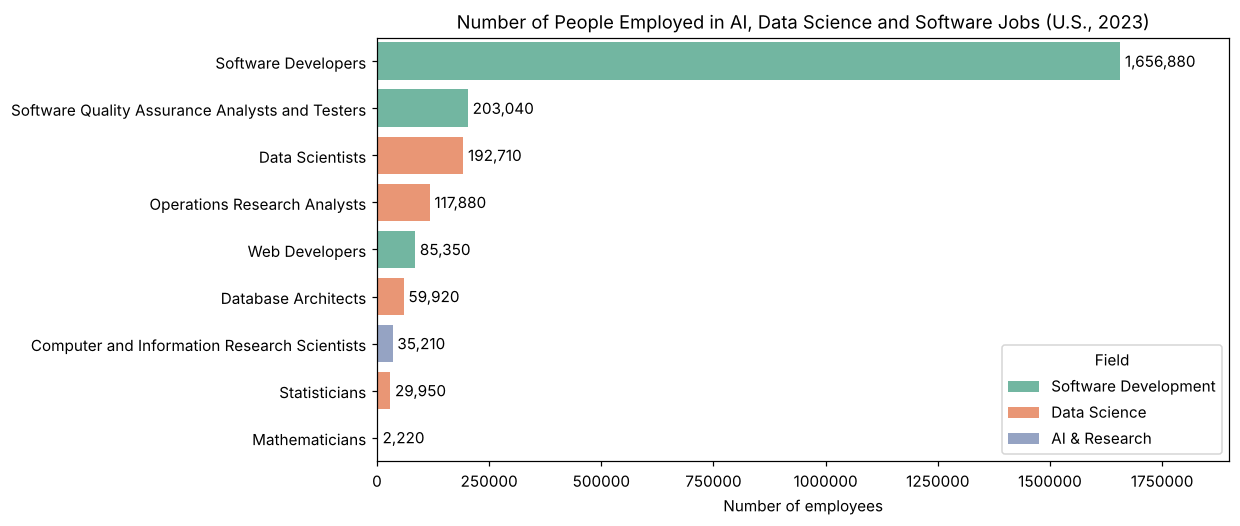

In [3]:
tech = tech.sort_values("TOT_EMP", ascending=False)

plt.figure(figsize=(10, 5))
ax = sns.barplot(x="TOT_EMP", y="OCC_TITLE", hue="Field", data=tech, dodge=False, palette="Set2")
for bars in ax.containers:                       # write the exact number at the end of each bar
    ax.bar_label(bars, fmt="{:,.0f}", padding=3)
plt.xlim(0, 1900000)
plt.title("Number of People Employed in AI, Data Science and Software Jobs (U.S., 2023)")
plt.xlabel("Number of employees")
plt.ylabel("")
plt.ticklabel_format(style="plain", axis="x")   # show 1600000 instead of 1.6 x 1e6
plt.show()

print(tech.groupby("Field")["TOT_EMP"].sum())
print("Total:", tech["TOT_EMP"].sum())

- **Objective:** Compare how many people work in each job and in each field (comparison).
- **Why this plot:** Each job is a category and its employment is a number, and bar length shows numbers accurately. The bars are horizontal because the job titles are long and are easier to read this way. They are sorted from largest to smallest, and the colour shows which field each job belongs to.
- **Learning:**
  - **Software Developers (about 1.66 million)** are by far the largest group, about **70 %** of everyone in these nine jobs.
  - **Data Scientists (about 193,000)** are the main data/AI job. There is about **one data scientist for every 8–9 software developers**.
  - **Computer and Information Research Scientists**, the closest match to "AI researcher", are only **about 35,000** people. Dedicated AI research is a very small, specialised workforce.
  - All nine jobs together are **about 2.4 million people, about 1.6 % of all U.S. jobs**. Most AI work is done by people with the job title "software developer" or "data scientist".

## 2. Boxplot – Salary Range for Each Job

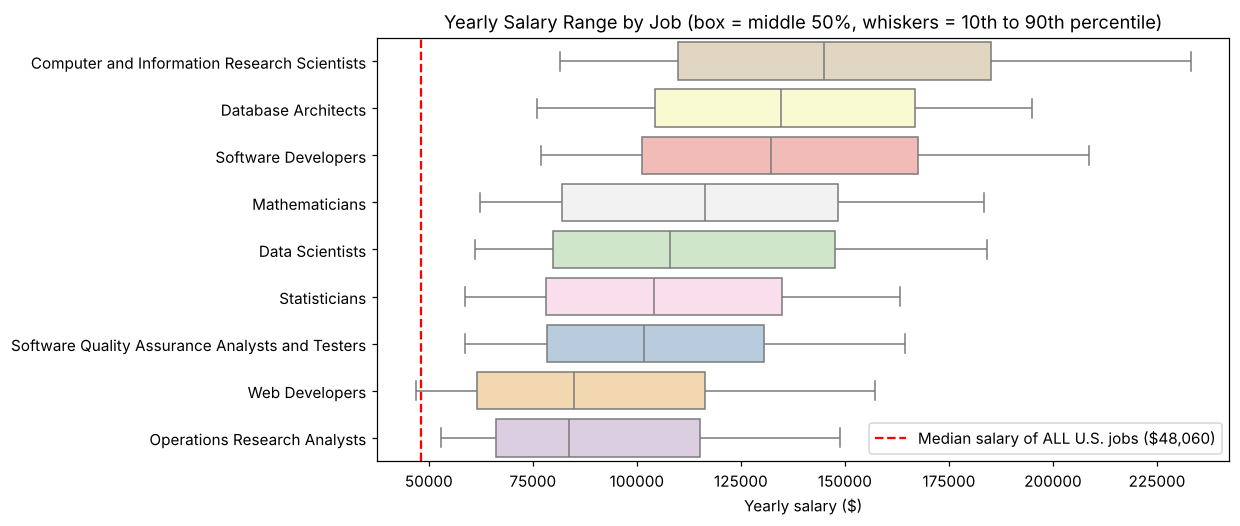

,OCC_TITLE,A_PCT10,A_MEDIAN,A_PCT90
138,Computer and Information Research Scientists,81450.0,145080.0,233110.0
145,Database Architects,76000.0,134700.0,194960.0
149,Software Developers,77020.0,132270.0,208620.0
159,Mathematicians,62260.0,116440.0,183500.0
165,Data Scientists,61070.0,108020.0,184090.0
163,Statisticians,58690.0,104110.0,163360.0
150,Software Quality Assurance Analysts and Testers,58740.0,101800.0,164520.0
151,Web Developers,46850.0,84960.0,157280.0
161,Operations Research Analysts,52930.0,83640.0,148920.0


In [4]:
# The dataset gives 5 salary points per job (10th, 25th, 50th, 75th, 90th percentile).
# We put them in long format so seaborn can draw a box for each job.
salaries = tech.melt(id_vars="OCC_TITLE",
                     value_vars=["A_PCT10", "A_PCT25", "A_MEDIAN", "A_PCT75", "A_PCT90"],
                     value_name="Salary")
order = tech.sort_values("A_MEDIAN", ascending=False)["OCC_TITLE"]

plt.figure(figsize=(10, 5))
sns.boxplot(x="Salary", y="OCC_TITLE", data=salaries, order=order, whis=(0, 100),
            hue="OCC_TITLE", palette="Pastel1", legend=False)
plt.axvline(48060, color="red", linestyle="--", label="Median salary of ALL U.S. jobs ($48,060)")
plt.title("Yearly Salary Range by Job (box = middle 50%, whiskers = 10th to 90th percentile)")
plt.xlabel("Yearly salary ($)")
plt.ylabel("")
plt.legend()
plt.show()

tech[["OCC_TITLE", "A_PCT10", "A_MEDIAN", "A_PCT90"]].sort_values("A_MEDIAN", ascending=False)

- **Objective:** Compare salaries across the jobs, and see how wide the pay range is inside each job (comparison and distribution).
- **Why this plot:** A boxplot shows the **median, the spread and the low and high ends** together, so it gives more information than a bar of the average. The BLS gives exactly the five numbers a boxplot needs (10th, 25th, 50th, 75th and 90th percentiles), so each box is drawn from those points. The red dashed line marks the median salary of *all* U.S. jobs for comparison.
- **Learning:**
  - **Every job's box is to the right of the red line.** Even the lowest-paid workers (10th percentile) in these jobs earn more than half of all U.S. workers.
  - **Computer and Information Research Scientists** (AI research) have the **highest median salary, about \$145,000**, which is **3 times** the U.S. median.
  - **Database Architects (\$135k)** and **Software Developers (\$132k)** come next. **Data Scientists (\$108k)** have a wide range (\$61k to \$184k), which shows a big difference between junior and senior roles.
  - **Web Developers** and **Operations Research Analysts** are the lowest-paid of the nine, at about \$84–85k.
  - The more specialised the job (research, architecture), the higher the pay.

## 3. Histogram – Salaries of All U.S. Jobs Compared with AI/Tech Jobs

Software Developers: earns more than 93% of all occupations
Software Quality Assurance Analysts and Testers: earns more than 87% of all occupations
Data Scientists: earns more than 90% of all occupations
Operations Research Analysts: earns more than 77% of all occupations
Web Developers: earns more than 79% of all occupations
Database Architects: earns more than 94% of all occupations
Computer and Information Research Scientists: earns more than 95% of all occupations
Statisticians: earns more than 88% of all occupations
Mathematicians: earns more than 91% of all occupations


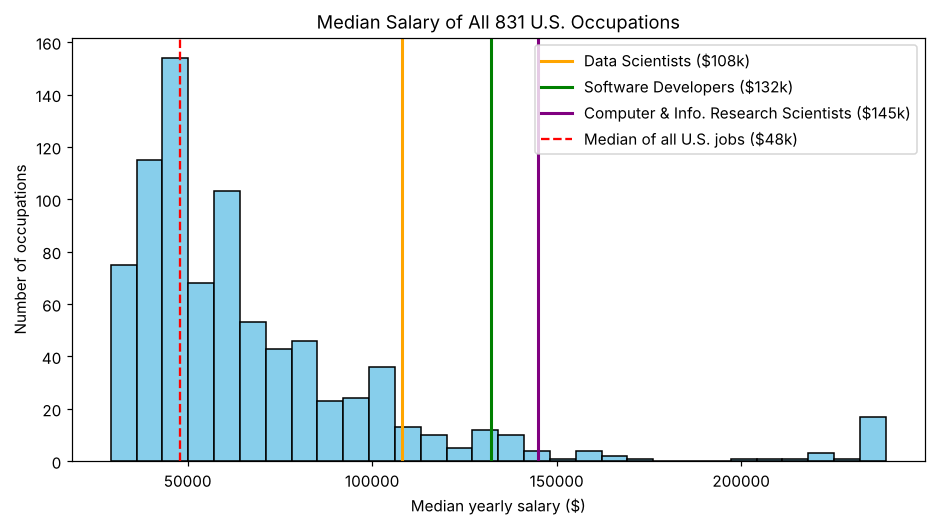

In [5]:
# Median salary of every detailed occupation in the U.S.
all_jobs = usa

plt.figure(figsize=(10, 5))
plt.hist(all_jobs["A_MEDIAN"].dropna(), bins=30, color="skyblue", edgecolor="black")

# Mark three of our jobs with vertical lines
plt.axvline(108020, color="orange", linewidth=2, label="Data Scientists ($108k)")
plt.axvline(132270, color="green", linewidth=2, label="Software Developers ($132k)")
plt.axvline(145080, color="purple", linewidth=2, label="Computer & Info. Research Scientists ($145k)")
plt.axvline(48060, color="red", linestyle="--", label="Median of all U.S. jobs ($48k)")

plt.title("Median Salary of All " + str(len(all_jobs)) + " U.S. Occupations")
plt.xlabel("Median yearly salary ($)")
plt.ylabel("Number of occupations")
plt.legend()
plt.show()

# What percentage of all occupations earn LESS than each of our jobs?
for job, salary in zip(tech["OCC_TITLE"], tech["A_MEDIAN"]):
    pct = (all_jobs["A_MEDIAN"] < salary).mean() * 100
    print(f"{job}: earns more than {pct:.0f}% of all occupations")

- **Objective:** Compare AI/tech salaries with **every** U.S. occupation, to see whether they really are high-paying jobs (comparison with context).
- **Why this plot:** Median salary is a continuous number, and there are about 830 occupations. A histogram groups them into salary ranges and shows the **shape** of the whole distribution. The coloured lines show where our jobs sit within it.
- **Learning:**
  - Most U.S. occupations have a median salary between **\$35,000 and \$70,000**. The distribution is **right-skewed**, with only a few jobs above \$100k.
  - Our jobs are in the **high-pay tail**. Research Scientists earn more than **95 %** of all occupations, Software Developers **93 %** and Data Scientists **90 %**. Even the lowest-paid, Web Developers and Operations Research Analysts, beat about **77–79 %**.
  - Almost all of the jobs that pay more are **doctors, surgeons and dentists**, plus **pilots, chief executives, senior managers and lawyers**.
  - Apart from medicine, law and senior management, AI and software jobs are among the best-paid in the country.

## 4. Pie Chart – Which Industries Employ Data Scientists

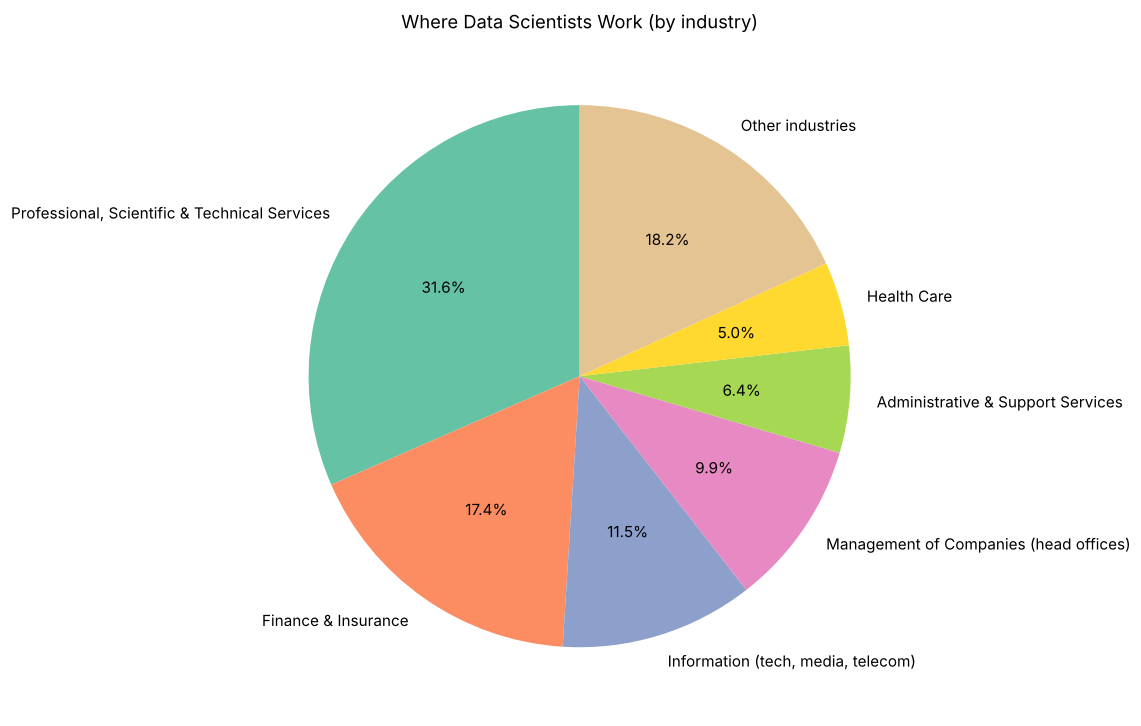

NAICS_TITLE
Professional, Scientific, and Technical Services                            60800.0
Finance and Insurance                                                       33620.0
Information                                                                 22240.0
Management of Companies and Enterprises                                     19060.0
Administrative and Support and Waste Management and Remediation Services    12310.0
Health Care and Social Assistance                                            9650.0
Other industries                                                            35010.0
Name: TOT_EMP, dtype: float64

In [6]:
# National data split by industry sector, for Data Scientists only
ds_industry = df[(df["AREA_TYPE"] == 1) & (df["I_GROUP"] == "sector") & (df["O_GROUP"] == "detailed")
                 & (df["OCC_TITLE"] == "Data Scientists")]
ds_industry = ds_industry.set_index("NAICS_TITLE")["TOT_EMP"].sort_values(ascending=False)

# Keep the 6 biggest industries and group the rest into "Other"
top6 = ds_industry.head(6)
top6["Other industries"] = ds_industry[6:].sum()

labels = ["Professional, Scientific & Technical Services", "Finance & Insurance", "Information (tech, media, telecom)",
          "Management of Companies (head offices)", "Administrative & Support Services", "Health Care", "Other industries"]

plt.figure(figsize=(8, 8))
plt.pie(top6, labels=labels, autopct="%1.1f%%", startangle=90, colors=sns.color_palette("Set2"))
plt.title("Where Data Scientists Work (by industry)")
plt.show()

top6

- **Objective:** Show which industries Data Scientists, the main AI/ML job, work in (whole-part relationship).
- **Why this plot:** Pie charts are good for whole-part relationships, here how 100 % of data scientists are split across industries. To keep it readable, only the **6 biggest industries** are shown and the rest are grouped into "Other".
- **Learning:**
  - **Professional, Scientific & Technical Services** (consulting, IT services, research companies) employ the most, about **one-third**. Much AI work is done as a *service* for other companies.
  - **Finance & Insurance (about 17 %)** is second. Banks and insurers use data science for fraud detection, credit risk and pricing.
  - **Information** (software, internet, telecom) and **company head offices** each employ about 10–12 %.
  - **Health care (5 %)**, manufacturing (4 %) and government (2 %) employ only a small share. AI talent is concentrated in a few industries, and other sectors still have room to grow.

## 5. Heatmap – Which States Specialise in AI/Data/Software Jobs

The **Location Quotient (LQ)** compares a state with the national average:
**LQ = 1** means the same as the U.S. average, **LQ = 2** means twice as concentrated, and **LQ = 0.5** means half.

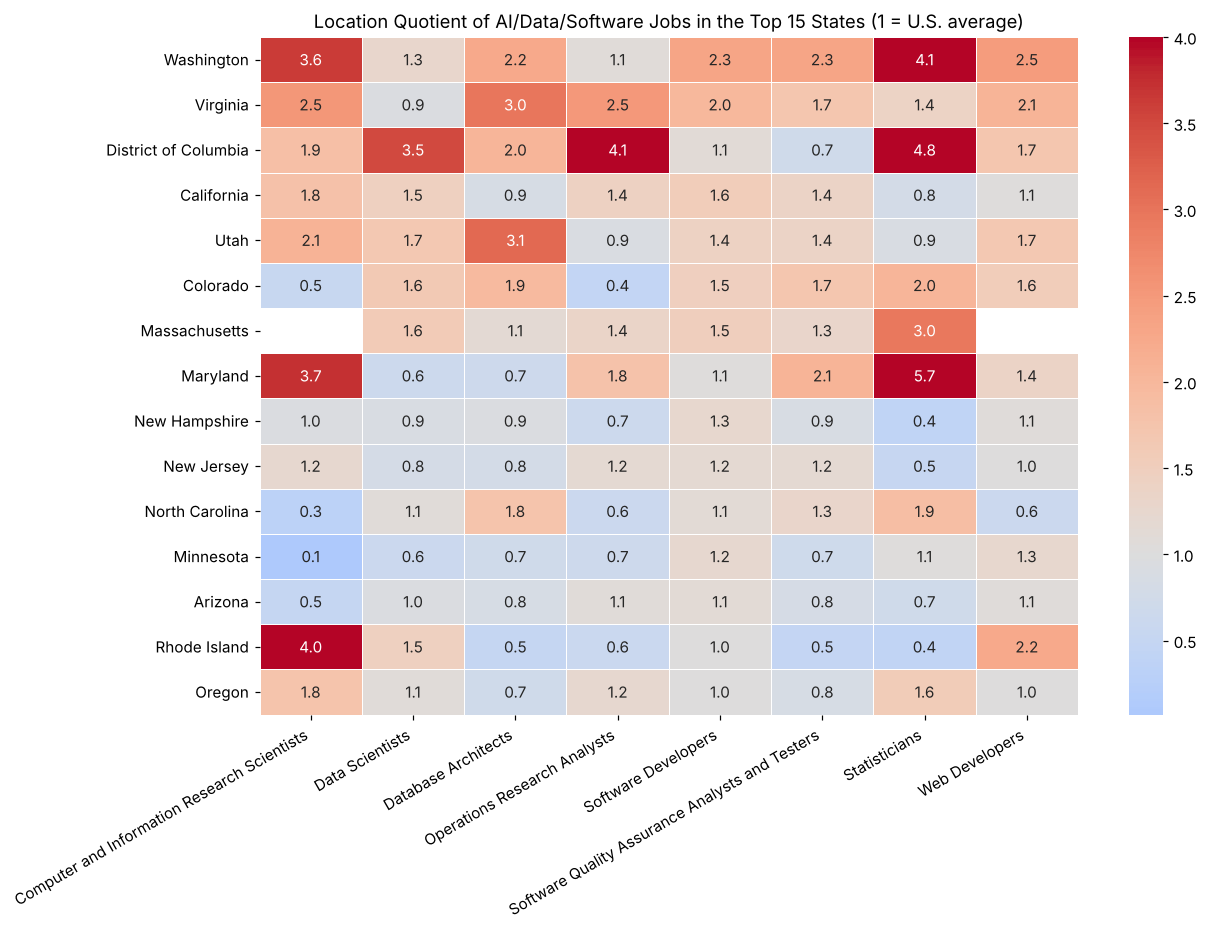

In [7]:
# State-level data (AREA_TYPE 2 = state), all industries, our nine jobs
states = df[(df["AREA_TYPE"] == 2) & (df["I_GROUP"] == "cross-industry") & (df["O_GROUP"] == "detailed")
            & (df["OCC_TITLE"].isin(fields.keys()))]

# Pick the 15 states with the most of these jobs per 1,000 workers
top_states = states.groupby("AREA_TITLE")["JOBS_1000"].sum().sort_values(ascending=False).head(15).index

# Table: rows = states, columns = jobs, values = location quotient (Mathematicians removed - mostly missing)
lq = states[states["AREA_TITLE"].isin(top_states)].pivot_table(index="AREA_TITLE", columns="OCC_TITLE", values="LOC_QUOTIENT")
lq = lq.drop(columns="Mathematicians").reindex(top_states)

plt.figure(figsize=(12, 8))
sns.heatmap(lq, annot=True, fmt=".1f", cmap="coolwarm", center=1, vmax=4, linewidths=0.5)
plt.title("Location Quotient of AI/Data/Software Jobs in the Top 15 States (1 = U.S. average)")
plt.xlabel("")
plt.ylabel("")
plt.xticks(rotation=30, ha="right")
plt.show()

- **Objective:** Find which states have unusually many of these jobs, and whether a state is strong in every job or only some (comparison across two categories).
- **Why this plot:** The data is a table of 15 states × 8 jobs (120 numbers). A heatmap shows the whole table at once, and colour makes the patterns easy to see. **Red = above the national average, blue = below.** Each cell also shows its number (`annot=True`). Blank cells are missing data.
- **Learning:**
  - **Washington state** (Microsoft, Amazon) is **red in almost every column**, so it is strong in all types of tech work. Its Software Developer LQ (2.3) is the highest of any state.
  - **Washington D.C., Maryland and Virginia** have very high values for **Statisticians, Operations Research Analysts and Data Scientists** (D.C. Data Scientists = 3.5). The federal government and defence contractors create a "government data science" hub.
  - **Research Scientists** (AI research) are most concentrated in **Rhode Island (4.0), Maryland (3.7), Washington (3.6) and Virginia (2.5)**. Small states can get high values from only a few hundred jobs.
  - **California** has the largest *number* of these jobs, but relative to its huge economy it is about **1.5×** the average for Data Scientists and Software Developers, not the highest.
  - Lower down the list, cells turn **blue**. Most states are close to average for software jobs but below average for specialist AI/data jobs. AI jobs are **clustered in a few hubs**.